In [1]:
!pwd

/home/ylnner/Documents/omnet++/omnetpp-6.3.0/projects/florasat_v4_ult_routing/simulations/Test_Individual/results


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
import matplotlib.image as mpimg
from scipy.spatial.distance import cdist
import os

number_of_runs = 10

# Read Metrics for Transformer ML Model

In [3]:
# Load the CSV files 

folder = "results_florasat_ml_trf"

'''
vector_files = [os.path.join(folder, f"wML_Transformer_{i}_vector.csv") for i in range(0, number_of_runs)]
scalar_files = [os.path.join(folder, f"wML_Transformer_{i}_scalar.csv") for i in range(0, number_of_runs)]

vector_dfs = [pd.read_csv(f) for f in vector_files]
scalar_dfs = [pd.read_csv(f) for f in scalar_files]
'''


thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
transformer_vector_dfs = {}
transformer_scalar_dfs = {}

for th in thresholds:
    transformer_vector_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_Transformer_threshold_{th}_{seed}_vector.csv")) for seed in range(number_of_runs)]
    transformer_scalar_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_Transformer_threshold_{th}_{seed}_scalar.csv")) for seed in range(number_of_runs)]

In [4]:
transformer_run_stats_msg_trx_at_dev = {}

for th, seed_dfs in transformer_scalar_dfs.items():
    #mean_values = []
    max_values = []
    min_values = []
    count_values = []
    #all_values = []
    for dataR in seed_dfs:
        transmitted_msg_df = dataR[dataR['name'].str.contains('transmittedMessages', na=False)]

        values = []
        for val in transmitted_msg_df['value']:
            values.extend(float(v) for v in str(val).strip('"').split())
        
        max_values.append(np.max(values) if values else 0)
        min_values.append(np.min(values) if values else 0)
        count_values.append(sum(values))        

    transformer_run_stats_msg_trx_at_dev[th] = {
        #'meanTrxAtDev': np.mean(all_values),
        'avgMaxMsgTrxAtDev': np.mean(max_values),
        'avgMinMsgTrxAtDev': np.mean(min_values),
        'avgCountMsgTrxAtDev': np.mean(count_values)
    }

In [5]:
# Number of repetitions required for successful reception at satellite
transformer_run_stats_rep_num_at_sat = {}
for th, seed_dfs in transformer_vector_dfs.items():
    #print(f"Processing threshold: {th}")    
    max_values = []
    min_values = []

    # Count of repetitions required for successful reception at satellite counted by the ML model and by the KiWan MAC protocol.
    count_reps_model = [] 
    count_reps_mac   = []

    # Total unique packets received at satellite counted by the ML model and by the KiWan MAC protocol.
    total_pkt_values_model  = []
    total_pkt_values_mac    = []

    for dataR in seed_dfs:        
        vector_model_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for the Model', na=False)]
        all_values_model = []

        for vec in vector_model_df['vecvalue']:
            all_values_model.extend(int(val) for val in str(vec).strip('"').split())

        max_values.append(np.max(all_values_model) if all_values_model else 0)
        min_values.append(np.min(all_values_model) if all_values_model else 0)
        count_reps_model.append(sum(all_values_model)) # sum of all repetitions required to recevive in the satellite.
        total_pkt_values_model.append(len(all_values_model)) # total number of packets.


        vector_mac_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for MAC protocol', na=False)]
        all_values_mac = []
        for vec in vector_mac_df['vecvalue']:
            all_values_mac.extend(int(val) for val in str(vec).strip('"').split())
        
        count_reps_mac.append(sum(all_values_mac)) # sum of all repetitions required to recevive in the satellite for the KiWan
        total_pkt_values_mac.append(len(all_values_mac)) # total number of packets for the KiWan
        
    transformer_run_stats_rep_num_at_sat[th] = {
        'avgMaxRepAtSat': np.mean(max_values),
        'avgMinRepAtSat': np.mean(min_values),
        'avgCountRepAtSatMac': np.mean(count_reps_mac),
        'avgTotalPktAtSatMac': np.mean(total_pkt_values_mac),
        'avgCountRepAtSatModel': np.mean(count_reps_model),
        'avgTotalPktAtSatModel': np.mean(total_pkt_values_model)
    }

print(len(transformer_run_stats_rep_num_at_sat))
#transformer_run_stats_rep_num_at_sat[0.6]
#transformer_run_stats_rep_num_at_sat

10


# Read Metrics for BiLSTM ML model

In [6]:
# Load the CSV files 

folder = "results_florasat_ml_lstm"

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
bilstm_vector_dfs = {}
bilstm_scalar_dfs = {}

#wML_BiLSTM_threshold_0.95_4_vector.csv
for th in thresholds:
    bilstm_vector_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_BiLSTM_threshold_{th}_{seed}_vector.csv")) for seed in range(number_of_runs)]
    bilstm_scalar_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_BiLSTM_threshold_{th}_{seed}_scalar.csv")) for seed in range(number_of_runs)]

In [7]:
bilstm_run_stats_msg_trx_at_dev = {}

for th, seed_dfs in bilstm_scalar_dfs.items():
    #mean_values = []
    max_values = []
    min_values = []
    count_values = []
    #all_values = []
    for dataR in seed_dfs:
        transmitted_msg_df = dataR[dataR['name'].str.contains('transmittedMessages', na=False)]

        values = []
        for val in transmitted_msg_df['value']:
            values.extend(float(v) for v in str(val).strip('"').split())

        #mean_values.append(np.mean(values) if values else 0)
        max_values.append(np.max(values) if values else 0)
        min_values.append(np.min(values) if values else 0)
        count_values.append(sum(values))
        #all_values.extend(values)        

    bilstm_run_stats_msg_trx_at_dev[th] = {
        #'meanTrxAtDev': np.mean(all_values),
        'avgMaxMsgTrxAtDev': np.mean(max_values),
        'avgMinMsgTrxAtDev': np.mean(min_values),
        'avgCountMsgTrxAtDev': np.mean(count_values)
    }

In [8]:
# Number of repetitions required for successful reception at satellite
bilstm_run_stats_rep_num_at_sat = {}
for th, seed_dfs in bilstm_vector_dfs.items():

    #print(f"Processing threshold: {th}")    
    max_values = []
    min_values = []

    # Count of repetitions required for successful reception at satellite counted by the ML model and by the KiWan MAC protocol.
    count_reps_model = [] 
    count_reps_mac   = []

    # Total unique packets received at satellite counted by the ML model and by the KiWan MAC protocol.
    total_pkt_values_model  = []
    total_pkt_values_mac    = []


    for dataR in seed_dfs:
        vector_model_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for the Model', na=False)]
        all_values_model = []

        for vec in vector_model_df['vecvalue']:
            all_values_model.extend(int(val) for val in str(vec).strip('"').split())

        max_values.append(np.max(all_values_model) if all_values_model else 0)
        min_values.append(np.min(all_values_model) if all_values_model else 0)
        count_reps_model.append(sum(all_values_model)) # sum of all repetitions required to recevive in the satellite.
        total_pkt_values_model.append(len(all_values_model)) # total number of packets.


        vector_mac_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for MAC protocol', na=False)]
        all_values_mac = []
        for vec in vector_mac_df['vecvalue']:
            all_values_mac.extend(int(val) for val in str(vec).strip('"').split())
        
        count_reps_mac.append(sum(all_values_mac)) # sum of all repetitions required to recevive in the satellite for the KiWan
        total_pkt_values_mac.append(len(all_values_mac)) # total number of packets for the KiWan


    #print('count_values: ' , sum(count_values), count_values)
    bilstm_run_stats_rep_num_at_sat[th] = {
        'avgMaxRepAtSat': np.mean(max_values),
        'avgMinRepAtSat': np.mean(min_values),
        'avgCountRepAtSatMac': np.mean(count_reps_mac),
        'avgTotalPktAtSatMac': np.mean(total_pkt_values_mac),
        'avgCountRepAtSatModel': np.mean(count_reps_model),
        'avgTotalPktAtSatModel': np.mean(total_pkt_values_model)
    }

# Read Metrics for Analytical

In [9]:
# Load the CSV files 

folder = "results_florasat_analytical"

#thresholds = [0.0005 ,0.0010 ,0.0015 ,0.0020 ,0.0025 ,0.00293 ,0.0035 ,0.0040 ,0.0050 ,0.0075]
#thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
#thresholds = [0.0008, 0.0010, 0.0012, 0.0014, 0.0016, 0.001787, 0.0020, 0.0022, 0.0025,0.0030]
thresholds = [0.0008, 0.0010, 0.0012, 0.0014, 0.0016, 0.001787, 0.0020, 0.0022, 0.0025,0.0030, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
thresholds = [0.00001,0.00010,0.00025,0.00050,0.00075,0.00100,0.00125,0.00150,0.00165,0.001787,0.00190,0.00210,0.00250,0.00350,0.00500,0.00750,0.01000,0.02000,0.05000,0.10000]

#vector_dfs = {}
analytical_scalar_dfs = {}

for th in thresholds:
    #vector_dfs[th] = [pd.read_csv(os.path.join(folder, f"wAnalytical_threshold_{th}_{seed}_vector.csv")) for seed in range(number_of_runs)]
    analytical_scalar_dfs[th] = [pd.read_csv(os.path.join(folder, f"wAnalytical_threshold_{th}_{seed}_scalar.csv")) for seed in range(number_of_runs)]

In [10]:
analytical_vector_dfs = {}

for th in thresholds:
    dfs = []

    for seed in range(number_of_runs):
        filename = os.path.join(folder, f"wAnalytical_threshold_{th}_{seed}_vector.csv")

        try:
            dfs.append(pd.read_csv(filename))
        except FileNotFoundError:
            pass

    analytical_vector_dfs[th] = dfs

In [11]:
analytical_run_stats_msg_trx_at_dev = {}

for th, seed_dfs in analytical_scalar_dfs.items():
    #mean_values = []
    max_values = []
    min_values = []
    count_values = []
    #all_values = []
    for dataR in seed_dfs:
        transmitted_msg_df = dataR[dataR['name'].str.contains('transmittedMessages', na=False)]

        values = []
        for val in transmitted_msg_df['value']:
            values.extend(float(v) for v in str(val).strip('"').split())

        #mean_values.append(np.mean(values) if values else 0)
        max_values.append(np.max(values) if values else 0)
        min_values.append(np.min(values) if values else 0)
        count_values.append(sum(values))
        #all_values.extend(values)

    analytical_run_stats_msg_trx_at_dev[th] = {
        #'meanTrxAtDev': np.mean(all_values),
        'avgMaxMsgTrxAtDev': np.mean(max_values),
        'avgMinMsgTrxAtDev': np.mean(min_values),
        'avgCountMsgTrxAtDev': np.mean(count_values)
    }

In [12]:
# Number of repetitions required for successful reception at satellite
analytical_run_stats_rep_num_at_sat = {}
for th, seed_dfs in analytical_vector_dfs.items():
    if not seed_dfs:
        analytical_run_stats_rep_num_at_sat[th] = {
            'maxRepAtSat': 0,
            'minRepAtSat': 0,
            'countRepAtSat': 0
        }
        continue

    #print(f"Processing threshold: {th}")    
    max_values = []
    min_values = []

    # Count of repetitions required for successful reception at satellite counted by the ML model and by the KiWan MAC protocol.
    count_reps_model = [] 
    count_reps_mac   = []

    # Total unique packets received at satellite counted by the ML model and by the KiWan MAC protocol.
    total_pkt_values_model  = []
    total_pkt_values_mac    = []
    
    for dataR in seed_dfs:
        vector_model_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for the Model', na=False)]
        all_values_model = []

        for vec in vector_model_df['vecvalue']:
            all_values_model.extend(int(val) for val in str(vec).strip('"').split())

        max_values.append(np.max(all_values_model) if all_values_model else 0)
        min_values.append(np.min(all_values_model) if all_values_model else 0)
        count_reps_model.append(sum(all_values_model)) # sum of all repetitions required to recevive in the satellite.
        total_pkt_values_model.append(len(all_values_model)) # total number of packets.

        vector_mac_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for MAC protocol', na=False)]
        all_values_mac = []
        for vec in vector_mac_df['vecvalue']:
            all_values_mac.extend(int(val) for val in str(vec).strip('"').split())
        
        count_reps_mac.append(sum(all_values_mac)) # sum of all repetitions required to recevive in the satellite for the KiWan
        total_pkt_values_mac.append(len(all_values_mac)) # total number of packets for the KiWan


    analytical_run_stats_rep_num_at_sat[th] = {
        'avgMaxRepAtSat': np.mean(max_values),
        'avgMinRepAtSat': np.mean(min_values),
        'avgCountRepAtSatMac': np.mean(count_reps_mac),
        'avgTotalPktAtSatMac': np.mean(total_pkt_values_mac),
        'avgCountRepAtSatModel': np.mean(count_reps_model),
        'avgTotalPktAtSatModel': np.mean(total_pkt_values_model)
    }

#print(len(analytical_run_stats_rep_num_at_sat))
#analytical_run_stats_rep_num_at_sat[0.95]

In [13]:
analytical_run_stats_rep_num_at_sat

{1e-05: {'avgMaxRepAtSat': np.float64(5.0),
  'avgMinRepAtSat': np.float64(1.2),
  'avgCountRepAtSatMac': np.float64(314.2),
  'avgTotalPktAtSatMac': np.float64(88.5),
  'avgCountRepAtSatModel': np.float64(314.0),
  'avgTotalPktAtSatModel': np.float64(88.5)},
 0.0001: {'avgMaxRepAtSat': np.float64(5.0),
  'avgMinRepAtSat': np.float64(1.2),
  'avgCountRepAtSatMac': np.float64(314.3),
  'avgTotalPktAtSatMac': np.float64(88.6),
  'avgCountRepAtSatModel': np.float64(314.0),
  'avgTotalPktAtSatModel': np.float64(88.6)},
 0.00025: {'avgMaxRepAtSat': np.float64(5.0),
  'avgMinRepAtSat': np.float64(1.2),
  'avgCountRepAtSatMac': np.float64(315.8),
  'avgTotalPktAtSatMac': np.float64(88.9),
  'avgCountRepAtSatModel': np.float64(315.5),
  'avgTotalPktAtSatModel': np.float64(88.9)},
 0.0005: {'avgMaxRepAtSat': np.float64(5.0),
  'avgMinRepAtSat': np.float64(1.2),
  'avgCountRepAtSatMac': np.float64(315.4),
  'avgTotalPktAtSatMac': np.float64(88.9),
  'avgCountRepAtSatModel': np.float64(315.1),
  

# Read Metrics for NoML

In [13]:
# Load the CSV files 

folder = "results_florasat_no_ml"

# wNoML_3_scalar
# wNoML_run_1_vector
vector_files = [os.path.join(folder, f"wNoML_run_{i}_vector.csv") for i in range(0, number_of_runs)]
scalar_files = [os.path.join(folder, f"wNoML_run_{i}_scalar.csv") for i in range(0, number_of_runs)]

no_ml_vector_dfs = [pd.read_csv(f) for f in vector_files]
no_ml_scalar_dfs = [pd.read_csv(f) for f in scalar_files]

'''
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
transformer_vector_dfs = {}
transformer_scalar_dfs = {}

for th in thresholds:
    transformer_vector_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_Transformer_threshold_{th}_{seed}_vector.csv")) for seed in range(number_of_runs)]
    transformer_scalar_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_Transformer_threshold_{th}_{seed}_scalar.csv")) for seed in range(number_of_runs)]
'''

'\nthresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]\ntransformer_vector_dfs = {}\ntransformer_scalar_dfs = {}\n\nfor th in thresholds:\n    transformer_vector_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_Transformer_threshold_{th}_{seed}_vector.csv")) for seed in range(number_of_runs)]\n    transformer_scalar_dfs[th] = [pd.read_csv(os.path.join(folder, f"wML_Transformer_threshold_{th}_{seed}_scalar.csv")) for seed in range(number_of_runs)]\n'

In [14]:
no_ml_run_stats_msg_trx_at_dev = []

for run_idx, dataR in enumerate(no_ml_scalar_dfs):
    transmitted_msg_df = dataR[dataR['name'].str.contains('transmittedMessages', na=False)].copy()
    
    values = []    
    for val in transmitted_msg_df['value']:        
        values.extend([float(v) for v in str(val).strip('"').split()])
    
    no_ml_run_stats_msg_trx_at_dev.append({
        'meanMsgTrxAtDev': np.mean(values) if values else 0,
        'maxMsgTrxAtDev': np.max(values) if values else 0,
        'minMsgTrxAtDev': np.min(values) if values else 0,
        'countMsgTrxAtDev': int(sum(values))
    })

In [15]:
# Number of repetitions required for successful reception at satellite
no_ml_run_stats_rep_num_at_sat = []

for run_idx, dataR in enumerate(no_ml_vector_dfs):
    nodeGenDelayRep_df = dataR[dataR['name'].str.contains('Successful Repetition Number counted for MAC protocol', na=False)].copy()
    all_reps = []
    for vec in nodeGenDelayRep_df['vecvalue']:
        all_reps.extend([int(val) for val in str(vec).strip('"').split()])
    #print('all_reps: ', all_reps)
    no_ml_run_stats_rep_num_at_sat.append({
        #'meanRepAtSat': np.mean(all_reps) if all_reps else 0,
        'avgMaxRepAtSat': np.max(all_reps) if all_reps else 0,
        'avgMinRepAtSat': np.min(all_reps) if all_reps else 0,
        'avgCountRepAtSatMac': sum(all_reps), 
        'avgTotalPktAtSatMac': len(all_reps),
        'avgCountRepAtSatModel': sum(all_reps), 
        'avgTotalPktAtSatModel': len(all_reps),
    })
no_ml_run_stats_rep_num_at_sat

[{'avgMaxRepAtSat': np.int64(5),
  'avgMinRepAtSat': np.int64(1),
  'avgCountRepAtSatMac': 269,
  'avgTotalPktAtSatMac': 76,
  'avgCountRepAtSatModel': 269,
  'avgTotalPktAtSatModel': 76},
 {'avgMaxRepAtSat': np.int64(5),
  'avgMinRepAtSat': np.int64(1),
  'avgCountRepAtSatMac': 352,
  'avgTotalPktAtSatMac': 100,
  'avgCountRepAtSatModel': 352,
  'avgTotalPktAtSatModel': 100},
 {'avgMaxRepAtSat': np.int64(5),
  'avgMinRepAtSat': np.int64(2),
  'avgCountRepAtSatMac': 316,
  'avgTotalPktAtSatMac': 84,
  'avgCountRepAtSatModel': 316,
  'avgTotalPktAtSatModel': 84},
 {'avgMaxRepAtSat': np.int64(5),
  'avgMinRepAtSat': np.int64(1),
  'avgCountRepAtSatMac': 301,
  'avgTotalPktAtSatMac': 83,
  'avgCountRepAtSatModel': 301,
  'avgTotalPktAtSatModel': 83},
 {'avgMaxRepAtSat': np.int64(5),
  'avgMinRepAtSat': np.int64(2),
  'avgCountRepAtSatMac': 249,
  'avgTotalPktAtSatMac': 73,
  'avgCountRepAtSatModel': 249,
  'avgTotalPktAtSatModel': 73},
 {'avgMaxRepAtSat': np.int64(5),
  'avgMinRepAtSat': 

In [16]:
finalAvgCountRepAtSatModel = np.mean([item['avgCountRepAtSatMac'] for item in no_ml_run_stats_rep_num_at_sat])
finalAvgTotalPktAtSatModel = np.mean([item['avgTotalPktAtSatMac'] for item in no_ml_run_stats_rep_num_at_sat])

print("Final Average Count of Repetitions at Satellite:", finalAvgCountRepAtSatModel)
print("Final Average Total Packets at Satellite:", finalAvgTotalPktAtSatModel)

Final Average Count of Repetitions at Satellite: 295.6
Final Average Total Packets at Satellite: 83.1


# Preprocess to create plot

In [17]:

rows = []

# Suponiendo que los tres diccionarios tienen los mismos thresholds
for th in sorted(transformer_run_stats_rep_num_at_sat.keys()):

    trf_dev = transformer_run_stats_msg_trx_at_dev.get(th, {})
    bilstm_dev = bilstm_run_stats_msg_trx_at_dev.get(th, {})
    analytical_dev = analytical_run_stats_msg_trx_at_dev.get(th, {})

    trf_sat = transformer_run_stats_rep_num_at_sat.get(th, {})
    bilstm_sat = bilstm_run_stats_rep_num_at_sat.get(th, {})
    analytical_sat = analytical_run_stats_rep_num_at_sat.get(th, {})

    if th not in analytical_run_stats_rep_num_at_sat.keys():        
        analytical_avgMaxRepAtSat = 0
        analytical_avgMinRepAtSat = 0
        analytical_avgCountRepAtSatMac   = 0
        analytical_avgCountRepAtSatModel = 0
        analytical_avgTotalPktAtSatMac   = 0
        analytical_avgTotalPktAtSatModel = 0
        analytical_avgMaxMsgTrxAtDev = 0
        analytical_avgMinMsgTrxAtDev = 0
        analytical_avgCountMsgTrxAtDev = 0
    else:
        analytical_avgMaxRepAtSat = analytical_sat.get("avgMaxRepAtSat", 0)
        analytical_avgMinRepAtSat = analytical_sat.get("avgMinRepAtSat", 0)
        analytical_avgCountRepAtSatMac = analytical_sat.get("avgCountRepAtSatMac", 0)
        analytical_avgCountRepAtSatModel = analytical_sat.get("avgCountRepAtSatModel", 0)
        analytical_avgTotalPktAtSatMac = analytical_sat.get("avgTotalPktAtSatMac", 0)
        analytical_avgTotalPktAtSatModel = analytical_sat.get("avgTotalPktAtSatModel", 0)

        analytical_avgMaxMsgTrxAtDev = analytical_dev.get("avgMaxMsgTrxAtDev", 0)
        analytical_avgMinMsgTrxAtDev = analytical_dev.get("avgMinMsgTrxAtDev", 0)
        analytical_avgCountMsgTrxAtDev = analytical_dev.get("avgCountMsgTrxAtDev", 0)

    rows.append({
        "threshold": th,

        "transformer_avgMaxRepAtSat": trf_sat.get("avgMaxRepAtSat", 0),
        "transformer_avgMinRepAtSat": trf_sat.get("avgMinRepAtSat", 0),
        "transformer_avgCountRepAtSatMac": trf_sat.get("avgCountRepAtSatMac", 0),
        "transformer_avgCountRepAtSatModel": trf_sat.get("avgCountRepAtSatModel", 0),
        "transformer_avgTotalPktAtSatMac": trf_sat.get("avgTotalPktAtSatMac", 0),
        "transformer_avgTotalPktAtSatModel": trf_sat.get("avgTotalPktAtSatModel", 0),

        "transformer_avgMaxMsgTrxAtDev": trf_dev.get("avgMaxMsgTrxAtDev", 0),
        "transformer_avgMinMsgTrxAtDev": trf_dev.get("avgMinMsgTrxAtDev", 0),
        "transformer_avgCountMsgTrxAtDev": trf_dev.get("avgCountMsgTrxAtDev", 0),


        "bilstm_avgMaxRepAtSat": bilstm_sat.get("avgMaxRepAtSat", 0),
        "bilstm_avgMinRepAtSat": bilstm_sat.get("avgMinRepAtSat", 0),
        "bilstm_avgCountRepAtSatMac": bilstm_sat.get("avgCountRepAtSatMac", 0),
        "bilstm_avgCountRepAtSatModel": bilstm_sat.get("avgCountRepAtSatModel", 0),
        "bilstm_avgTotalPktAtSatMac": bilstm_sat.get("avgTotalPktAtSatMac", 0),        
        "bilstm_avgTotalPktAtSatModel": bilstm_sat.get("avgTotalPktAtSatModel", 0),

        "bilstm_avgMaxMsgTrxAtDev": bilstm_dev.get("avgMaxMsgTrxAtDev", 0),
        "bilstm_avgMinMsgTrxAtDev": bilstm_dev.get("avgMinMsgTrxAtDev", 0),
        "bilstm_avgCountMsgTrxAtDev": bilstm_dev.get("avgCountMsgTrxAtDev", 0),

        "analytical_avgMaxRepAtSat": analytical_avgMaxRepAtSat,
        "analytical_avgMinRepAtSat": analytical_avgMinRepAtSat,
        "analytical_avgCountRepAtSatMac": analytical_avgCountRepAtSatMac,
        "analytical_avgCountRepAtSatModel": analytical_avgCountRepAtSatModel,        
        "analytical_avgTotalPktAtSatMac": analytical_avgTotalPktAtSatMac,
        "analytical_avgTotalPktAtSatModel": analytical_avgTotalPktAtSatModel,

        "analytical_avgMaxMsgTrxAtDev": analytical_avgMaxMsgTrxAtDev,
        "analytical_avgMinMsgTrxAtDev": analytical_avgMinMsgTrxAtDev,
        "analytical_avgCountMsgTrxAtDev": analytical_avgCountMsgTrxAtDev,

    })


for th in sorted(analytical_run_stats_rep_num_at_sat.keys()):
    if th not in [row["threshold"] for row in rows]:
    #if th not in [row["threshold"] for row in rows]:
        analytical_dev = analytical_run_stats_msg_trx_at_dev.get(th, {})
        analytical_sat = analytical_run_stats_rep_num_at_sat.get(th, {})

        rows.append({
            "threshold": th,

            "transformer_avgMaxRepAtSat": 0,
            "transformer_avgMinRepAtSat": 0,
            "transformer_avgCountRepAtSat": 0,
            "transformer_avgTotalPktAtSat": 0,

            "transformer_avgMaxMsgTrxAtDev": 0,
            "transformer_avgMinMsgTrxAtDev": 0,
            "transformer_avgCountMsgTrxAtDev": 0,

            "bilstm_avgMaxRepAtSat": 0,
            "bilstm_avgMinRepAtSat": 0,
            "bilstm_avgCountRepAtSat": 0,
            "bilstm_avgTotalPktAtSat": 0,

            "bilstm_avgMaxMsgTrxAtDev": 0,
            "bilstm_avgMinMsgTrxAtDev": 0,
            "bilstm_avgCountMsgTrxAtDev": 0,

            "analytical_avgMaxRepAtSat": analytical_sat.get("avgMaxRepAtSat", 0),
            "analytical_avgMinRepAtSat": analytical_sat.get("avgMinRepAtSat", 0),
            "analytical_avgCountRepAtSatMac": analytical_sat.get("avgCountRepAtSatMac", 0),
            "analytical_avgCountRepAtSatModel": analytical_sat.get("avgCountRepAtSatModel", 0),
            "analytical_avgTotalPktAtSatMac": analytical_sat.get("avgTotalPktAtSatMac", 0),
            "analytical_avgTotalPktAtSatModel": analytical_sat.get("avgTotalPktAtSatModel", 0),

            "analytical_avgMaxMsgTrxAtDev": analytical_dev.get("avgMaxMsgTrxAtDev", 0),
            "analytical_avgMinMsgTrxAtDev": analytical_dev.get("avgMinMsgTrxAtDev", 0),
            "analytical_avgCountMsgTrxAtDev": analytical_dev.get("avgCountMsgTrxAtDev", 0),
        })

df = pd.DataFrame(rows)
df.to_csv("comparison_rep_num_at_sat.csv", index=False)

In [23]:
df[['threshold', 
    'transformer_avgCountRepAtSatMac', 'transformer_avgCountRepAtSatModel', 'transformer_avgTotalPktAtSatMac', 'transformer_avgTotalPktAtSatModel',
    'bilstm_avgCountRepAtSatMac', 'bilstm_avgCountRepAtSatModel',
    'analytical_avgCountRepAtSatMac', 'analytical_avgCountRepAtSatModel', 'analytical_avgTotalPktAtSatModel']]#.to_csv("comparison_rep_num_at_sat_filtered.csv", index=False)  

,threshold,transformer_avgCountRepAtSatMac,transformer_avgCountRepAtSatModel,transformer_avgTotalPktAtSatMac,transformer_avgTotalPktAtSatModel,bilstm_avgCountRepAtSatMac,bilstm_avgCountRepAtSatModel,analytical_avgCountRepAtSatMac,analytical_avgCountRepAtSatModel,analytical_avgTotalPktAtSatModel
0,0.100000,302.3,302.2,85.1,85.1,300.3,300.3,316.9,316.9,89.4
1,0.200000,310.5,308.8,87.5,87.5,315.8,311.1,0.0,0.0,0.0
2,0.300000,332.0,327.8,93.3,93.3,326.6,310.9,0.0,0.0,0.0
3,0.400000,328.7,313.8,94.3,94.3,305.7,289.1,0.0,0.0,0.0
4,0.500000,297.8,280.2,88.7,88.7,292.2,271.0,0.0,0.0,0.0
5,0.600000,265.8,248.6,80.8,80.8,266.5,242.3,0.0,0.0,0.0
6,0.700000,218.1,193.4,70.6,70.6,228.4,194.4,0.0,0.0,0.0
7,0.800000,156.3,131.5,54.5,54.5,137.6,107.8,0.0,0.0,0.0
8,0.900000,87.2,67.2,31.6,31.6,49.1,42.8,0.0,0.0,0.0
9,0.950000,42.8,32.8,15.8,15.8,30.4,29.6,0.0,0.0,0.0


# Generate graphics

10
20
Processing model: Transformer-Encoder
Processing model: BiLSTM
Processing model: Analytical


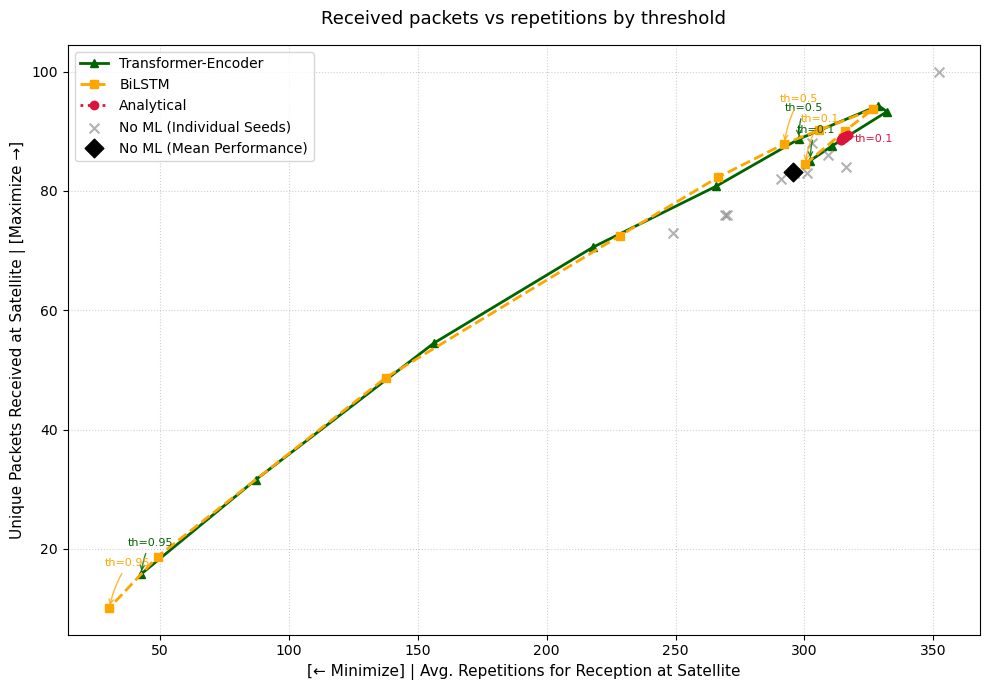

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
#from sympy import Ellipse
from matplotlib.patches import Ellipse

df = pd.read_csv("comparison_rep_num_at_sat.csv")

th_bilstm_transformer = [0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,0.950000]
#th_analytical = [0.0008, 0.0010, 0.0012, 0.0014, 0.0016, 0.001787, 0.0020, 0.0022, 0.0025,0.0030, 0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,0.950000]
th_analytical = [0.00001,0.00010,0.00025,0.00050,0.00075,0.00100,0.00125,0.00150,0.00165,0.001787,0.00190,0.00210,0.00250,0.00350,0.00500,0.00750,0.01000,0.02000,0.05000,0.10000]

print(len(th_bilstm_transformer))
print(len(th_analytical))


''' 
"No ML": {
    "color": "black",
    "x": "avgCountRepAtSat", 
    "y": "avgTotalPktAtSat", 
    "marker": "X",
    "ls": "-.",  # Línea discontinua punto-raya para diferenciarla
    "is_static_list": True,
},
'''
modelos = {
    "Transformer-Encoder": {
        "x": "transformer_avgCountRepAtSatMac",
        "y": "transformer_avgTotalPktAtSatMac",
        "color": "darkgreen",
        "marker": "^",
        "ls": "-"
    },
    "BiLSTM": {
        "x": "bilstm_avgCountRepAtSatMac",
        "y": "bilstm_avgTotalPktAtSatMac",
        "color": "orange",
        "marker": "s",
        "ls": "--"
    },
    "Analytical": {
        "x": "analytical_avgCountRepAtSatModel",
        "y": "analytical_avgTotalPktAtSatModel",
        "color": "crimson",
        "marker": "o",
        "ls": ":"
    }
}

plt.figure(figsize=(10, 7))
for model, config in modelos.items():
    #df_sorted = df.sort_values(by="threshold")
    print(f"Processing model: {model}")
    ''' 
    if model == "No ML":
        df_static = pd.DataFrame(no_ml_run_stats_rep_num_at_sat)
        df_sorted = df_static.sort_values(by='avgCountRepAtSat')
        thresholds = np.array([])  # No ML no tiene thresholds
        th_to_plot = []
    '''
    if model == "Transformer-Encoder" or model == "BiLSTM":
        thresholds = np.array(th_bilstm_transformer)
        aux_df = df[df["threshold"].isin(th_bilstm_transformer)]
        df_sorted = aux_df.sort_values(by="threshold")
        th_to_plot = [0.1, 0.5, 0.95]
    elif model == "Analytical":
        thresholds = np.array(th_analytical)
        aux_df = df[df["threshold"].isin(th_analytical)]
        df_sorted = aux_df.sort_values(by="threshold")
        th_to_plot = [0.0008, 0.0030, 0.1] #0.0016,
    
    x_vals = df_sorted[config["x"]].to_numpy(dtype=float)
    y_vals = df_sorted[config["y"]].to_numpy(dtype=float)


    #if model != "No ML":
    mask = x_vals != 0
    x_vals = x_vals[mask]
    y_vals = y_vals[mask]
    thresholds = thresholds[mask]
    
    plt.plot(x_vals, y_vals, label=model, color=config["color"], linestyle=config["ls"], marker=config["marker"], linewidth=2, markersize=6)
    
    for idx in range(len(thresholds)):
        th = thresholds[idx]
        if th not in th_to_plot:
            continue

        if model == "Transformer-Encoder":
            offset_x, offset_y = -10, 20
        elif model == "BiLSTM":
            offset_x, offset_y = -3, 30 #-18
        else:
            offset_x, offset_y = 5, -5
        
        #offset_x, offset_y = 0, 0
        plt.annotate(
            f"th={thresholds[idx]}",
            (x_vals[idx], y_vals[idx]),
            xytext=(offset_x, offset_y),
            textcoords="offset points",
            fontsize=8,
            color=config["color"],
            #weight='bold' if "Transformer" in nombre_modelo else 'normal'
            #weight = 'normal'
            arrowprops=dict(
                arrowstyle="->",
                color=config["color"],
                lw=1,
                alpha=0.8,
                connectionstyle="arc3,rad=0.1"  # Curvatura elegante en la flecha
            )
        )


# --- 2. Graficar No ML como Nube y Región Estadística ---
df_no_ml = pd.DataFrame(no_ml_run_stats_rep_num_at_sat)
x_no_ml = df_no_ml["avgCountRepAtSatModel"].to_numpy()
y_no_ml = df_no_ml["avgTotalPktAtSatModel"].to_numpy()

# Nube de puntos gris (seeds individuales)
plt.scatter(x_no_ml, y_no_ml, color="gray", alpha=0.6, marker="x", s=50, label="No ML (Individual Seeds)", zorder=2)

# Diamante negro central (promedio estadístico)
mean_x = np.mean(x_no_ml)
mean_y = np.mean(y_no_ml)
plt.scatter(mean_x, mean_y, color="black", marker="D", s=90, label="No ML (Mean Performance)", zorder=4)

''' 
# Elipse de confianza estadística construida sobre la matriz de covarianza real
cov = np.cov(x_no_ml, y_no_ml)
lambda_, v = np.linalg.eig(cov)
ell = Ellipse(
    xy=(mean_x, mean_y), 
    width=np.sqrt(lambda_[0]) * 2.5, 
    height=np.sqrt(lambda_[1]) * 2.5, 
    angle=np.degrees(np.arctan2(v[1, 0], v[0, 0])), 
    color="gray", 
    alpha=0.12,
    linestyle="--",
    label="No ML (Seed Variance Region)"
)
plt.gca().add_patch(ell)
'''

plt.title("Received packets vs repetitions by threshold", fontsize=13, pad=15)
plt.ylabel("Unique Packets Received at Satellite | [Maximize →]", fontsize=11)
plt.xlabel("[← Minimize] | Avg. Repetitions for Reception at Satellite", fontsize=11)

#plt.gca().invert_xaxis()
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left", fontsize=10) # lower left
plt.tight_layout()

plt.savefig("pareto_intuitivo_dtsiot.png", dpi=300)
plt.show()
plt.close()

# New Plot

In [19]:
models = {
    "Analytical": {
        "x": "analytical_avgCountRepAtSatModel",
        "y": "analytical_avgTotalPktAtSatModel",
        "color": "crimson",
        "marker": "o",
        "ls": ":"
    }
}

# Plotting Analytical Model
thresholds = np.array(th_analytical)
aux_df = df[df["threshold"].isin(th_analytical)]
df_sorted = aux_df.sort_values(by="threshold")
th_to_plot = [0.0008, 0.0030, 0.1] #0.0016,

x_vals = df_sorted[models["Analytical"]["x"]].to_numpy(dtype=float)
y_vals = df_sorted[models["Analytical"]["y"]].to_numpy(dtype=float)

len(x_vals)

20

10
20
Processing model: Transformer-Encoder
Processing model: BiLSTM
Analytical thresholds to plot: [0.001787]
Annotating threshold 0.001787 at index 9 with coordinates (315.1, 88.9)


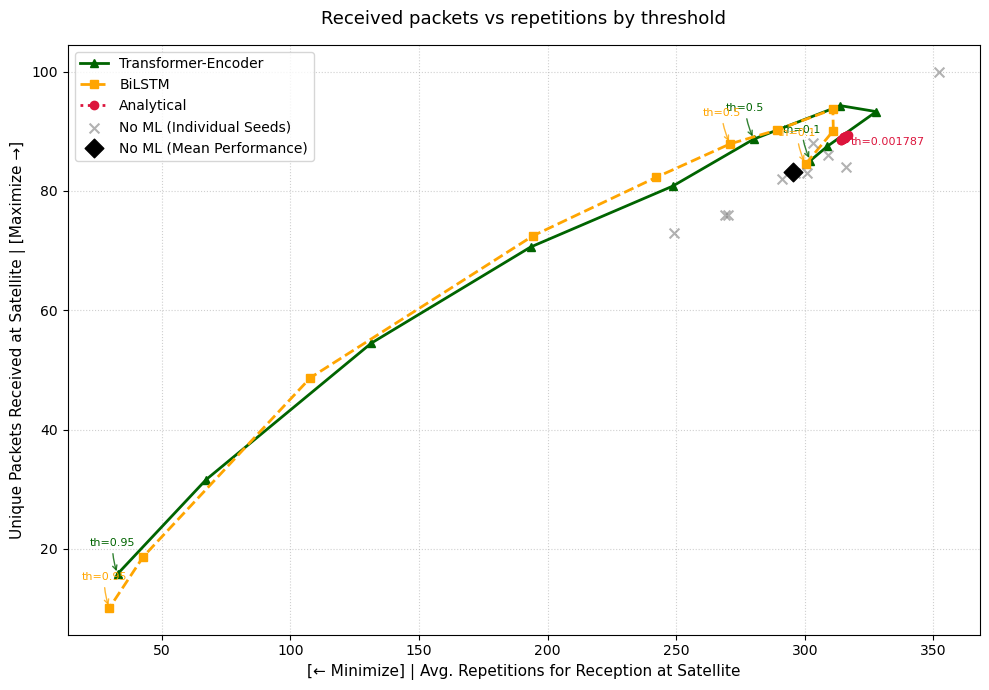

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
#from sympy import Ellipse
from matplotlib.patches import Ellipse

df = pd.read_csv("comparison_rep_num_at_sat.csv")

th_bilstm_transformer = [0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,0.950000]
#th_analytical = [0.0008, 0.0010, 0.0012, 0.0014, 0.0016, 0.001787, 0.0020, 0.0022, 0.0025,0.0030, 0.100000,0.200000,0.300000,0.400000,0.500000,0.600000,0.700000,0.800000,0.900000,0.950000]
th_analytical = [0.00001,0.00010,0.00025,0.00050,0.00075,0.00100,0.00125,0.00150,0.00165,0.001787,0.00190,0.00210,0.00250,0.00350,0.00500,0.00750,0.01000,0.02000,0.05000,0.10000]
                  
print(len(th_bilstm_transformer))
print(len(th_analytical))

models = {
    "Transformer-Encoder": {
        "x": "transformer_avgCountRepAtSatModel",
        "y": "transformer_avgTotalPktAtSatModel",
        "color": "darkgreen",
        "marker": "^",
        "ls": "-"
    },
    "BiLSTM": {
        "x": "bilstm_avgCountRepAtSatModel",
        "y": "bilstm_avgTotalPktAtSatModel",
        "color": "orange",
        "marker": "s",
        "ls": "--"
    }
}

plt.figure(figsize=(10, 7))
for model, config in models.items():    
    print(f"Processing model: {model}")
        
    thresholds = np.array(th_bilstm_transformer)
    aux_df = df[df["threshold"].isin(th_bilstm_transformer)]
    df_sorted = aux_df.sort_values(by="threshold")

    if model == "Transformer-Encoder":
        th_to_plot = [0.1, 0.5, 0.95]
    elif model == "BiLSTM":
        th_to_plot = [0.1, 0.5, 0.95]

    x_vals = df_sorted[config["x"]].to_numpy(dtype=float)
    y_vals = df_sorted[config["y"]].to_numpy(dtype=float)


    #if model != "No ML":
    mask = x_vals != 0
    x_vals = x_vals[mask]
    y_vals = y_vals[mask]
    thresholds = thresholds[mask]
    
    plt.plot(x_vals, y_vals, label=model, color=config["color"], linestyle=config["ls"], marker=config["marker"], linewidth=2, markersize=6)
    
    for idx in range(len(thresholds)):
        th = thresholds[idx]
        if th not in th_to_plot:
            continue

        if model == "Transformer-Encoder":
            offset_x, offset_y = -20, 20
        elif model == "BiLSTM":
            offset_x, offset_y = -20, 20 #-18
        else:
            offset_x, offset_y = 5, -5
        
        #offset_x, offset_y = 0, 0
        plt.annotate(
            f"th={thresholds[idx]}",
            (x_vals[idx], y_vals[idx]),
            xytext=(offset_x, offset_y),
            textcoords="offset points",
            fontsize=8,
            color=config["color"],
            #weight='bold' if "Transformer" in nombre_modelo else 'normal'
            #weight = 'normal'
            arrowprops=dict(
                arrowstyle="->",
                color=config["color"],
                lw=1,
                alpha=0.8,
                connectionstyle="arc3,rad=0.1"  # Curvatura elegante en la flecha
            )
        )


models = {
    "Analytical": {
        "x": "analytical_avgCountRepAtSatModel",
        "y": "analytical_avgTotalPktAtSatModel",
        "color": "crimson",
        "marker": "o",
        "ls": ":"
    }
}

# Plotting Analytical Model
thresholds = np.array(th_analytical)
aux_df = df[df["threshold"].isin(th_analytical)]
df_sorted = aux_df.sort_values(by="threshold")
th_to_plot = [0.001787]#[0.00075, 0.0035, 0.1] #[0.0008, 0.0030, 0.1] #0.0016,

x_vals = df_sorted[models["Analytical"]["x"]].to_numpy(dtype=float)
y_vals = df_sorted[models["Analytical"]["y"]].to_numpy(dtype=float)


#if model != "No ML":
mask = x_vals != 0
x_vals = x_vals[mask]
y_vals = y_vals[mask]
thresholds = thresholds[mask]

plt.plot(x_vals, y_vals, label="Analytical", color=models["Analytical"]["color"], linestyle=models["Analytical"]["ls"], marker=models["Analytical"]["marker"], linewidth=2, markersize=6)

print('Analytical thresholds to plot:', th_to_plot)
for idx in range(len(thresholds)):
    th = thresholds[idx]
    if th not in th_to_plot:
        continue
    print(f"Annotating threshold {th} at index {idx} with coordinates ({x_vals[idx]}, {y_vals[idx]})")
    offset_x, offset_y = 5, -5
    
    #offset_x, offset_y = 0, 0
    plt.annotate(
        f"th={thresholds[idx]}",
        (x_vals[idx], y_vals[idx]),
        xytext=(offset_x, offset_y),
        textcoords="offset points",
        fontsize=8,
        color=models["Analytical"]["color"],
        #weight='bold' if "Transformer" in nombre_modelo else 'normal'
        #weight = 'normal'
        arrowprops=dict(
            arrowstyle="->",
            color=models["Analytical"]["color"],
            lw=1,
            alpha=0.8,
            connectionstyle="arc3,rad=0.1"  # Curvatura elegante en la flecha
        )
    )

# Plotting No ML 
df_no_ml = pd.DataFrame(no_ml_run_stats_rep_num_at_sat)
x_no_ml = df_no_ml["avgCountRepAtSatModel"].to_numpy()
y_no_ml = df_no_ml["avgTotalPktAtSatModel"].to_numpy()

# Plot individual seeds
plt.scatter(x_no_ml, y_no_ml, color="gray", alpha=0.6, marker="x", s=50, label="No ML (Individual Seeds)", zorder=2)

# Plot avg point
mean_x = np.mean(x_no_ml)
mean_y = np.mean(y_no_ml)
plt.scatter(mean_x, mean_y, color="black", marker="D", s=90, label="No ML (Mean Performance)", zorder=4)



plt.title("Received packets vs repetitions by threshold", fontsize=13, pad=15)
plt.ylabel("Unique Packets Received at Satellite | [Maximize →]", fontsize=11)
plt.xlabel("[← Minimize] | Avg. Repetitions for Reception at Satellite", fontsize=11)

#plt.gca().invert_xaxis()
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left", fontsize=10) # lower left
plt.tight_layout()

plt.savefig("pareto_intuitivo_dtsiot.png", dpi=300)
plt.show()
plt.close()

In [71]:
df.columns

Index(['threshold', 'transformer_avgMaxRepAtSat', 'transformer_avgMinRepAtSat',
       'transformer_avgCountRepAtSatMac', 'transformer_avgCountRepAtSatModel',
       'transformer_avgTotalPktAtSatMac', 'transformer_avgTotalPktAtSatModel',
       'transformer_avgMaxMsgTrxAtDev', 'transformer_avgMinMsgTrxAtDev',
       'transformer_avgCountMsgTrxAtDev', 'bilstm_avgMaxRepAtSat',
       'bilstm_avgMinRepAtSat', 'bilstm_avgCountRepAtSatMac',
       'bilstm_avgCountRepAtSatModel', 'bilstm_avgTotalPktAtSatMac',
       'bilstm_avgTotalPktAtSatModel', 'bilstm_avgMaxMsgTrxAtDev',
       'bilstm_avgMinMsgTrxAtDev', 'bilstm_avgCountMsgTrxAtDev',
       'analytical_avgMaxRepAtSat', 'analytical_avgMinRepAtSat',
       'analytical_avgCountRepAtSatMac', 'analytical_avgCountRepAtSatModel',
       'analytical_avgTotalPktAtSatMac', 'analytical_avgTotalPktAtSatModel',
       'analytical_avgMaxMsgTrxAtDev', 'analytical_avgMinMsgTrxAtDev',
       'analytical_avgCountMsgTrxAtDev', 'transformer_avgCountRepAtSa

In [75]:
df[df["threshold"] == 0.1][['threshold','bilstm_avgCountRepAtSatMac', 'bilstm_avgCountRepAtSatModel', 'bilstm_avgTotalPktAtSatMac', 'bilstm_avgTotalPktAtSatModel']]



,threshold,bilstm_avgCountRepAtSatMac,bilstm_avgCountRepAtSatModel,bilstm_avgTotalPktAtSatMac,bilstm_avgTotalPktAtSatModel
0,0.1,326.9,316.3,93.6,93.6


In [76]:
df[df["threshold"] == 0.7][['threshold','bilstm_avgCountRepAtSatMac', 'bilstm_avgCountRepAtSatModel', 'bilstm_avgTotalPktAtSatMac', 'bilstm_avgTotalPktAtSatModel']]



,threshold,bilstm_avgCountRepAtSatMac,bilstm_avgCountRepAtSatModel,bilstm_avgTotalPktAtSatMac,bilstm_avgTotalPktAtSatModel
6,0.7,329.6,191.2,95.5,95.5


In [24]:
df['bilstm_diffCountRepAtSat'] = df['bilstm_avgCountRepAtSatMac'] - df['bilstm_avgCountRepAtSatModel']
df['transformer_diffCountRepAtSat'] = df['transformer_avgCountRepAtSatMac'] - df['transformer_avgCountRepAtSatModel']
df['analytical_diffCountRepAtSat'] = df['analytical_avgCountRepAtSatMac'] - df['analytical_avgCountRepAtSatModel']

In [25]:
df[['threshold', 'bilstm_diffCountRepAtSat', 'transformer_diffCountRepAtSat', 'analytical_diffCountRepAtSat']]

,threshold,bilstm_diffCountRepAtSat,transformer_diffCountRepAtSat,analytical_diffCountRepAtSat
0,0.100000,0.0,0.1,0.0
1,0.200000,4.7,1.7,0.0
2,0.300000,15.7,4.2,0.0
3,0.400000,16.6,14.9,0.0
4,0.500000,21.2,17.6,0.0
5,0.600000,24.2,17.2,0.0
6,0.700000,34.0,24.7,0.0
7,0.800000,29.8,24.8,0.0
8,0.900000,6.3,20.0,0.0
9,0.950000,0.8,10.0,0.0
